# ImmoAnalyse — Exploration des résultats du pipeline

Ce notebook lit les fichiers produits par `python -m src.main` :
données propres, quarantaine et rapport de qualité.

**Avant de l'exécuter**, lance le pipeline depuis la racine du projet :
`python -m src.main`.

Les données sont synthétiques : elles ne servent pas à estimer le marché réel.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RACINE = Path("..")
propres = pd.read_csv(RACINE / "data" / "processed" / "donnees_propres.csv")
quarantaine = pd.read_csv(RACINE / "data" / "quarantine" / "quarantaine.csv")
doublons = pd.read_csv(RACINE / "data" / "quarantine" / "doublons_ecartes.csv")
regles = pd.read_csv(RACINE / "reports" / "quality_summary.csv")
with open(RACINE / "reports" / "quality_report.json", encoding="utf-8") as f:
    indicateurs = json.load(f)

print(len(propres), "retenues |", len(quarantaine), "en quarantaine |",
      len(doublons), "doublons écartés")

2924 retenues | 246 en quarantaine | 14 doublons écartés


## 1. Du brut aux données retenues

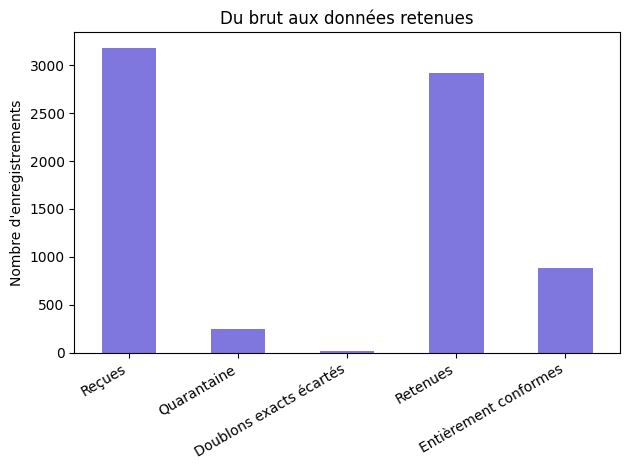

Taux global de conformité : 27.8 %


In [2]:
entonnoir = pd.Series({
    "Reçues": indicateurs["total_recus"],
    "Quarantaine": indicateurs["enregistrements_en_quarantaine"],
    "Doublons exacts écartés": indicateurs["enregistrements_ecartes_doublons"],
    "Retenues": indicateurs["enregistrements_retenus"],
    "Entièrement conformes": indicateurs["entierement_conformes"],
})
entonnoir.plot(kind="bar", color="#7F77DD")
plt.title("Du brut aux données retenues")
plt.ylabel("Nombre d'enregistrements")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()
print(f"Taux global de conformité : {indicateurs['taux_global_conformite_pct']} %")

## 2. Qualité par source

In [3]:
recues = pd.Series(indicateurs["recus_par_source"])
en_quarantaine = quarantaine["source"].value_counts()
par_source = pd.DataFrame({"recues": recues, "quarantaine": en_quarantaine}).fillna(0)
par_source["taux_quarantaine_pct"] = (par_source["quarantaine"] / par_source["recues"] * 100).round(1)
par_source.sort_values("taux_quarantaine_pct", ascending=False)

,recues,quarantaine,taux_quarantaine_pct
particuliers,731,136,18.6
agence,640,68,10.6
notaires,410,20,4.9
historique,528,10,1.9
plateforme,875,12,1.4


## 3. Pourquoi des lignes sont en quarantaine

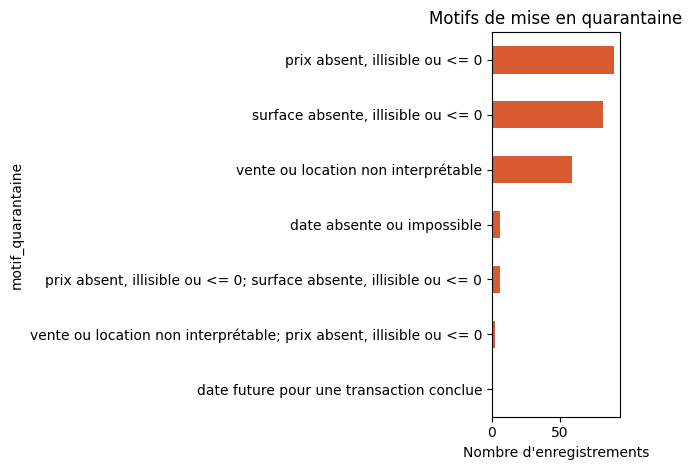

In [4]:
motifs = quarantaine["motif_quarantaine"].value_counts()
motifs.sort_values().plot(kind="barh", color="#D85A30")
plt.title("Motifs de mise en quarantaine")
plt.xlabel("Nombre d'enregistrements")
plt.tight_layout()
plt.show()

## 4. Conformité par règle

Taux = conformes / évaluables × 100. Les valeurs **non évaluables** sont comptées
à part : on ne les considère pas comme conformes.

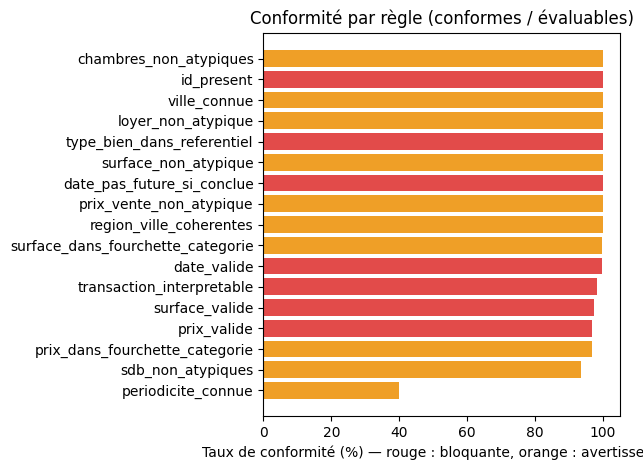

,regle,conformes,non_conformes,non_evaluables
0,id_present,3184,0,0
1,transaction_interpretable,3123,61,0
2,prix_valide,3086,98,0
3,surface_valide,3096,88,0
4,date_valide,3178,6,0
5,date_pas_future_si_conclue,1848,1,1335
6,type_bien_dans_referentiel,3184,0,0
7,surface_non_atypique,3096,4,84
8,prix_vente_non_atypique,2608,3,573
9,loyer_non_atypique,177,0,3007


In [5]:
tableau = regles.dropna(subset=["taux_conformite_pct"]).sort_values("taux_conformite_pct")
couleurs = ["#E24B4A" if g == "bloquante" else "#EF9F27" for g in tableau["gravite"]]
plt.barh(tableau["regle"], tableau["taux_conformite_pct"], color=couleurs)
plt.xlabel("Taux de conformité (%) — rouge : bloquante, orange : avertissement")
plt.title("Conformité par règle (conformes / évaluables)")
plt.tight_layout()
plt.show()
regles[["regle", "conformes", "non_conformes", "non_evaluables"]]

## 5. Avertissements les plus fréquents (lignes conservées)

In [6]:
(propres["avertissements"].dropna()
 .str.split("; ").explode().value_counts())

avertissements
périodicité du loyer inconnue                      219
plus de salles de bain que de chambres + 2         114
prix hors fourchette indicative du type de bien     80
ville et région incompatibles                        4
surface hors fourchette typique du type de bien      3
Name: count, dtype: int64

## 6. Prix au m² des ventes

On ne calcule le prix au m² que pour les **ventes** : un loyer n'est pas
comparable à un prix de vente. Ce sont des prix **demandés** (annonces),
pas des prix de transaction conclue.

count       2534.0
mean      735795.0
std       561671.0
min         6648.0
25%       353490.0
50%       624852.0
75%       979080.0
max      4603188.0
Name: prix_m2, dtype: float64


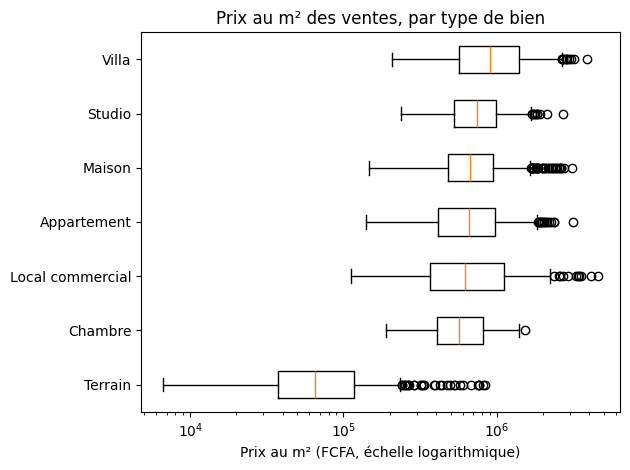

In [7]:
ventes = propres[propres["transaction"] == "vente"].copy()
ventes["prix_m2"] = ventes["prix_fcfa"] / ventes["surface_m2"]
print(ventes["prix_m2"].describe().round(0))

types = ventes.groupby("type_bien")["prix_m2"].median().sort_values().index
donnees_boite = [ventes.loc[ventes["type_bien"] == t, "prix_m2"] for t in types]
plt.boxplot(donnees_boite, tick_labels=types, vert=False)
plt.xscale("log")
plt.xlabel("Prix au m² (FCFA, échelle logarithmique)")
plt.title("Prix au m² des ventes, par type de bien")
plt.tight_layout()
plt.show()

## 7. Villes les plus chères (au moins 10 ventes)

In [8]:
(ventes.groupby("ville")["prix_m2"]
 .agg(nombre="count", mediane="median")
 .query("nombre >= 10")
 .sort_values("mediane", ascending=False)
 .head(10).round(0))

,nombre,mediane
ville,,
Dakar,44,1021546.0
Rufisque,54,807320.0
Pikine,42,780855.0
Saint-Louis,55,723157.0
Ourossogui,69,707205.0
Touba,45,706127.0
Kolda,55,704725.0
Birkelane,46,697893.0
Vélingara,62,696853.0


## 8. Les locations, séparément

In [9]:
loyers = propres[(propres["transaction"] == "location") & (propres["periodicite"] == "mensuel")]
print(len(loyers), "locations avec périodicité mensuelle connue")
loyers["prix_fcfa"].describe().round(0)

171 locations avec périodicité mensuelle connue


count        171.0
mean      395292.0
std       293078.0
min        40000.0
25%       187500.0
50%       315000.0
75%       542500.0
max      1480000.0
Name: prix_fcfa, dtype: float64

## Conclusions

*À écrire avec tes mots, en regardant tes graphiques :*

- **Qualité** : quelle source est la plus dégradée ? Pourquoi ?
- **Quarantaine** : quel est le motif principal ?
- **Prix** : que remarques-tu sur le prix au m² par type de bien ?
- **Limites** : données synthétiques, loyers sans périodicité, doublons probables non fusionnés.